# Research Question 1: ADHD Medication Adverse Event Reporting Patterns

## Setup

In [ ]:
import os
import duckdb

# Remove any MotherDuck token from this Python process.
os.environ.pop("MOTHERDUCK_TOKEN", None)

# Connect using MotherDuck's browser authentication.
con = duckdb.connect("md:")

# Verify the connection.
print(con.sql("SELECT 1 AS test").df())

   test
0     1


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Connect to FAERS ADHD table
con = duckdb.connect('md:_share/Capstone_faers_adhd_data_only/6fc22063-9b4d-4a08-843a-a3bb9391d9d5')
con.sql("SELECT pipeline_version, built_at_utc FROM study_build").df()

,pipeline_version,built_at_utc
0,0.27.0,2026-11-03T20:36:19Z


## Research Question

How do cardiovascular, psychiatric, and dependence-related adverse event reporting patterns differ between stimulant and nonstimulant medications, and how do these patterns vary by patient age and sex?

## Objective

The objective of this analysis is to examine differences in adverse reporting patterns between stimulant and nonstimulant ADHD medications using the FAERS data.

The analysis also investigates whether reporting patterns differ across patient agent grooups and sex.

### Variables Used in the Analysis
The following variables from the adhd_cases dataset were used to examine adverse event reporting patterns between stimulant and nonstimulant ADHD medications.

**caseid**: Unique identification number assigned to each adverse event case.

**rq1_group**: Classification of the ADHD medications associated with each case. Categories include STIMULANT, NONSTIMULANT, and MULTI_ADHD_CLASS.

**age_years**: Reported patient age in years. Missing values are represented as NULL.

**age_band_fine**: Patient age grouped into seven categories: 0-5, 6-11, 12-17, 18-25, 26-44, 45-64, and 65+.

**sex_category**: Reported patient sex, classified as male (M), female (F), or unknown (UNKNOWN). Some cases also contain missing values.

**cardiovascular_narrow**: Boolean indicator identifying whether a case contains an adverse event classified within the cardiovascular category.

**psychiatric_narrow**: Boolean indicator identifying whether a case contains an adverse event classified within the psychiatric category.

**dependence_narrow**: Boolean indicator identifying whether a case contains an adverse event classified within the dependence-related category.

### Calulated Variables

Additional variables were calculated during the exploratory analysis to compare adverse event reporting patterns.

**total_cases**: Total number of reported cases within a medication class or demographic group.

**cardiovascular_pct**: Percentage of cases within a group containing a cardiovascular adverse event flag.

**psychiatric_pct**: Percentage of cases within a group containing a psychiatric adverse event flag.

**dependence_pct**: Percentage of cases within a group containing a dependence-related adverse event flag.

## Analytical Approach

Descriptive statistics and visualizations will be used to compare the proportions of reported cases associated with each adverse event category.

## Dataset Overview

The analysis uses ADHD medication reports from the FDA Adverse Event System Reporting syste (FAERS), accessed through MotherDuck using duckDB.

The ```adhd_cases``` table contains 94,803 unique cases, including:
* 81,998 stimulant cases
* 11,805 nonstimulating cases
* 1,000 cases involving multiple ADHD medication classes

For the primary comparison, cases involving multiple ADHD medication classes are excluded to maintain distinct medication groups.

The analysis focuses on three adverse event categories: cardiovascular, psychiatric, and dependence-related events.

In [ ]:
# Summanry of the number of cases in each medication class.
class_counts = con.sql("""
    SELECT
        rq1_group,
        COUNT(*) AS total_cases
    FROM adhd_cases
    GROUP BY rq1_group
    ORDER BY total_cases DESC
""").df()

display(class_counts)

,rq1_group,total_cases
0,STIMULANT,81998
1,NONSTIMULANT,11805
2,MULTI_ADHD_CLASS,1000


## Missing Demographic Information

Initial data exploration identified substantial missing demographic information within the dataset.

Approximately 49.4% of cases are missing age information, while 20.4% contain NULL values for patient sex. An additional 2,144 cases are classified as UNKNOWN for sex.

Missing demoraphic may affect comparisons across patient groups. Therefore, demographic-specific analysis will report the number of cases available for each comparison.

In [ ]:
# Calculate missing demographic information.
missing_data = con.sql("""
    SELECT
        COUNT(*) AS total_cases,
        COUNT(*) FILTER (
            WHERE age_years IS NULL
        ) AS missing_age,
        COUNT(*) FILTER (
            WHERE age_band_fine IS NULL
        ) AS missing_age_band,
        COUNT(*) FILTER (
            WHERE sex_category IS NULL
               OR sex_category = 'UNKNOWN'
        ) AS missing_sex
    FROM adhd_cases
""").df()

# Convert the query results into a summary DataFrame.
total = missing_data["total_cases"].iloc[0]

missing_summary = pd.DataFrame({
    "Variable": ["Age", "Sex"],
    "Missing Cases": [
        missing_data["missing_age"].iloc[0],
        missing_data["missing_sex"].iloc[0]
    ]
})

# Calculate missing and available percentages.
missing_summary["Missing (%)"] = (
    missing_summary["Missing Cases"] / total * 100
).round(2)

missing_summary["Available (%)"] = (
    100 - missing_summary["Missing (%)"]
)

display(missing_summary)

,Variable,Missing Cases,Missing (%),Available (%)
0,Age,46873,49.44,50.56
1,Sex,21473,22.65,77.35


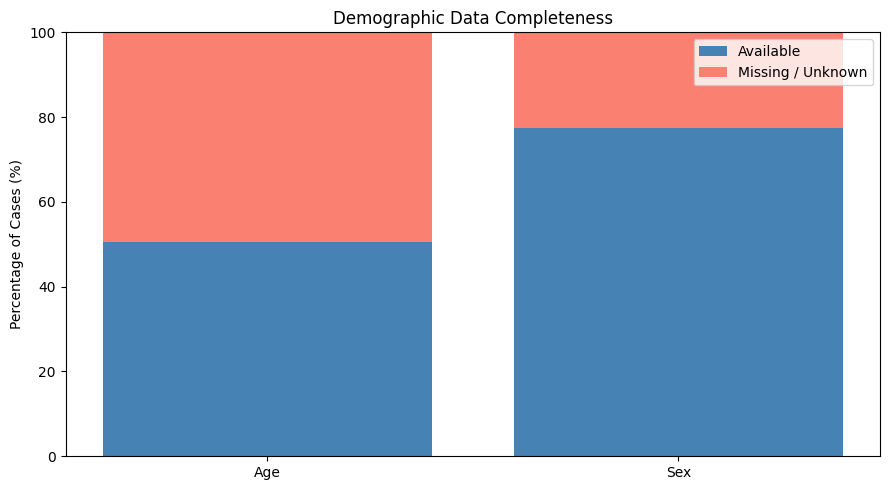

In [ ]:
# @title
# Calculate available percentages.
missing_summary["Available (%)"] = (
    100 - missing_summary["Missing (%)"]
)

fig, ax = plt.subplots(figsize=(9, 5))

# Plot available and missing percentages.
ax.bar(
    missing_summary["Variable"],
    missing_summary["Available (%)"],
    label="Available",
    color="steelblue"
)

ax.bar(
    missing_summary["Variable"],
    missing_summary["Missing (%)"],
    bottom=missing_summary["Available (%)"],
    label="Missing / Unknown",
    color="salmon"
)

ax.set_title("Demographic Data Completeness")
ax.set_ylabel("Percentage of Cases (%)")
ax.set_ylim(0, 100)
ax.legend()

plt.tight_layout()
fig.savefig("rq1_demographic_completeness.png", dpi=300, bbox_inches="tight")
plt.show()

## Overall Comparison by Medication Class

This analysis compares the proportion of stimulant and nonstimulant FAERS cases associated woth cardiovascular, psychiatric, and dependance-related adverse event categories.

Reporting proportions are calculated using the number of cases with each adverse event flag divided by the total number of class within the corresponding medication class.

In [ ]:
rq1_overall = con.sql("""
    SELECT
        rq1_group,
        COUNT(*) AS total_cases,
        COUNT(*) FILTER (
            WHERE cardiovascular_narrow = TRUE
        ) AS cardiovascular,
        COUNT(*) FILTER (
            WHERE psychiatric_narrow = TRUE
        ) AS psychiatric,
        COUNT(*) FILTER (
            WHERE dependence_narrow = TRUE
        ) AS dependence
    FROM adhd_cases
    WHERE rq1_group IN ('STIMULANT', 'NONSTIMULANT')
    GROUP BY rq1_group
    ORDER BY rq1_group
""").df()

for event in ("cardiovascular", "psychiatric", "dependence"):
    rq1_overall[f"{event}_pct"] = (
        rq1_overall[event] / rq1_overall["total_cases"] * 100
    ).round(2)

display(rq1_overall)

,rq1_group,total_cases,cardiovascular,psychiatric,dependence,cardiovascular_pct,psychiatric_pct,dependence_pct
0,NONSTIMULANT,11805,1724,3176,37,14.60,26.90,0.31
1,STIMULANT,81998,8295,17766,1213,10.12,21.67,1.48


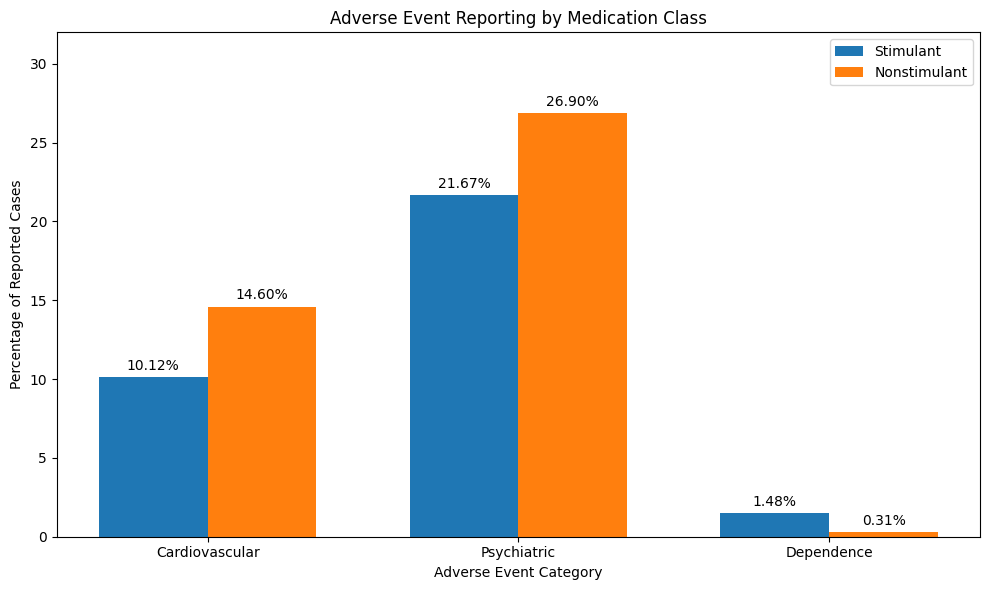

In [ ]:
# @title
# Event categories to compare.
events = ["Cardiovascular", "Psychiatric", "Dependence"]

# Retrieve reporting percentages for each medication class.
stimulant = rq1_overall.loc[
    rq1_overall["rq1_group"] == "STIMULANT",
    ["cardiovascular_pct", "psychiatric_pct", "dependence_pct"]
].iloc[0].to_numpy(dtype=float)

nonstimulant = rq1_overall.loc[
    rq1_overall["rq1_group"] == "NONSTIMULANT",
    ["cardiovascular_pct", "psychiatric_pct", "dependence_pct"]
].iloc[0].to_numpy(dtype=float)

# Set up bar positions and width.
x = np.arange(len(events))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Plot bars side by side for each adverse event category.
bars1 = ax.bar(x - width / 2, stimulant, width, label="Stimulant")
bars2 = ax.bar(x + width / 2, nonstimulant, width, label="Nonstimulant")

# Add labels and chart formatting.
ax.set_title("Adverse Event Reporting by Medication Class")
ax.set_xlabel("Adverse Event Category")
ax.set_ylabel("Percentage of Reported Cases")
ax.set_xticks(x)
ax.set_xticklabels(events)
ax.legend()

# Display the percentage above each bar.
ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

ax.set_ylim(0, 32)
plt.tight_layout()

fig.savefig("rq1_adverse_event_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

## Interpretation

Ther initial results indicate differences in adverse event reporting proportions between stimulant and nonstimulant medications.

Nonstimulant caseshad a higher proportions of cardiovascular (14.60%) and psychiatric (26.90%) event reports compared with stimulant cases (10.12% and 21.67%).

In contrast, dependence-related events were frequently flagged under stimuant cases (1.48%) than nonstimulant cases (0.31%).

These findings describe differences in FAERS reporting patterns and should not be interpreted as difference in medication safety.    

## Demographic Analysis: Age and Sex

This section examines how cardiovascular, psychiatric, and dependence-related adverse event reporting patterns vary across patients age groups and sex classicfications for stimulant and nonstimulant ADHD medications.

While the previous analysis identified differences in overall reporting proportions between the two medications classes, these patterns may also vary depending on patioent demographics. Examining age and sex together allows us to investigate whether differences in adverse event reporting are consitant across demographic groups or whether certain combinations exhibit distinct reporting patterns.

## Analytical Approach

The analysis will compare adverse event reporting proportions across seven age groups and two reported sex categories (male and female). Cases will be separated by medication classification to allow comparisons between stimulant and nonstimulant medications.

Reporting proportions will be calculated using the number of cases with a specified adverse event flag divided by the total number of cases within each medication class, age group, and sex category.

## Demographic Distribution

The distribution of reported cases varies across age groups, sex classifications, and medication classes. Stimulant medications accoubt for for more reports across all demographic groups, with the highest umber of cases occuring among patients between the age 16-44.

Male patients account for more reports in younger age groups, particularly ages 6-11 annd 12-17, while female patients account for more reports in most adult age groups. Some demographic groups , especially older patients receiving nonstimulant medications, contain relatively few cases. These differences in sample sizes will be considered when comparing adverse event reporting proportions.

In [ ]:
# @title
# Calculate adverse event counts by age, sex, and medication class.
age_sex_eda = con.sql("""
    SELECT
        rq1_group,
        age_band_fine AS age_group,
        sex_category,
        COUNT(*) AS total_cases,

        COUNT(*) FILTER (
            WHERE cardiovascular_narrow = TRUE
        ) AS cardiovascular,

        COUNT(*) FILTER (
            WHERE psychiatric_narrow = TRUE
        ) AS psychiatric,

        COUNT(*) FILTER (
            WHERE dependence_narrow = TRUE
        ) AS dependence

    FROM adhd_cases
    WHERE rq1_group IN ('STIMULANT', 'NONSTIMULANT')
      AND age_band_fine IS NOT NULL
      AND sex_category IN ('M', 'F')

    GROUP BY
        rq1_group,
        age_band_fine,
        sex_category

    ORDER BY
        age_group,
        sex_category,
        rq1_group
""").df()

# Calculate reporting percentages within each demographic group.
for event in ["cardiovascular", "psychiatric", "dependence"]:
    age_sex_eda[f"{event}_pct"] = (
        age_sex_eda[event] /
        age_sex_eda["total_cases"] * 100
    ).round(2)

display(age_sex_eda)

,rq1_group,age_group,sex_category,total_cases,cardiovascular,psychiatric,dependence,cardiovascular_pct,psychiatric_pct,dependence_pct
0,NONSTIMULANT,0_5,F,51,5,12,0,9.80,23.53,0.00
1,STIMULANT,0_5,F,293,32,39,0,10.92,13.31,0.00
2,NONSTIMULANT,0_5,M,132,15,36,0,11.36,27.27,0.00
3,STIMULANT,0_5,M,763,71,147,9,9.31,19.27,1.18
4,NONSTIMULANT,12_17,F,501,101,163,0,20.16,32.53,0.00
5,STIMULANT,12_17,F,2303,346,975,9,15.02,42.34,0.39
6,NONSTIMULANT,12_17,M,1040,176,317,0,16.92,30.48,0.00
7,STIMULANT,12_17,M,3753,436,952,30,11.62,25.37,0.80
8,NONSTIMULANT,18_25,F,373,111,125,5,29.76,33.51,1.34
9,STIMULANT,18_25,F,2405,453,818,25,18.84,34.01,1.04


## Findings and Observations

Cardiovascular adverse event reporting proportions generally increased across older age groups, although differences between stimulant and nonstimulant medications varied by age and sex. Nonstimulant medications showed higher cardiovascular reporting proportions in several adult demographic groups.

Psychiatric adverse event reporting patterns also varied across demographic groups. Among females aged 12-17, stimulant medications had a higher reporting proportion than nonstimulants (42.34% versus 32.53%). However, the opposite pattern was observed among males in the same age group, suggesting that reporting differences may vary by sex.

Dependence-related events were reported less frequently overall, with higher poroprtions generally observed among stimulant cases. The largest occured among males aged 26-44 receiving stimulant medications (4.61%). These findings suggest that age and sex may when examing differences in adverse event reporting between medication classes.

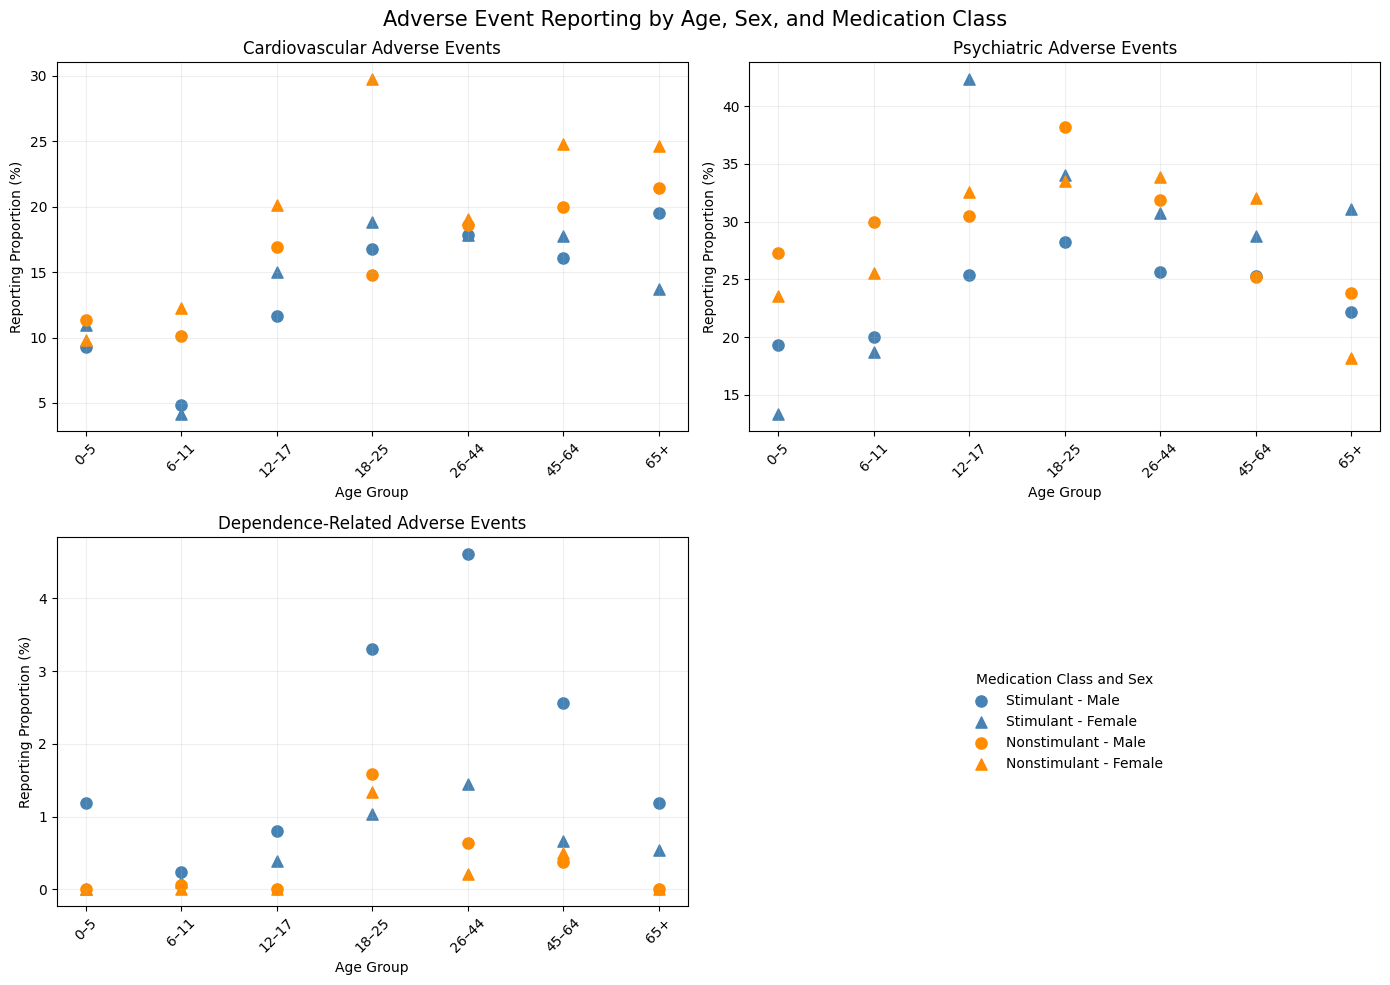

In [ ]:
# @title
age_order = ["0_5", "6_11", "12_17", "18_25",
             "26_44", "45_64", "65_PLUS"]

age_order = [
    "0_5", "6_11", "12_17", "18_25",
    "26_44", "45_64", "65_PLUS"
]

age_labels = [
    "0–5", "6–11", "12–17", "18–25",
    "26–44", "45–64", "65+"
]

# Create a figure with two rows and two columns.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Organize the data by medication class and sex.
stim_m = age_sex_eda[
    (age_sex_eda["rq1_group"] == "STIMULANT") &
    (age_sex_eda["sex_category"] == "M")
].set_index("age_group").reindex(age_order)

stim_f = age_sex_eda[
    (age_sex_eda["rq1_group"] == "STIMULANT") &
    (age_sex_eda["sex_category"] == "F")
].set_index("age_group").reindex(age_order)

nonstim_m = age_sex_eda[
    (age_sex_eda["rq1_group"] == "NONSTIMULANT") &
    (age_sex_eda["sex_category"] == "M")
].set_index("age_group").reindex(age_order)

nonstim_f = age_sex_eda[
    (age_sex_eda["rq1_group"] == "NONSTIMULANT") &
    (age_sex_eda["sex_category"] == "F")
].set_index("age_group").reindex(age_order)

x = np.arange(len(age_order))

# Cardiovascular

ax = axes[0, 0]

ax.scatter(x, stim_m["cardiovascular_pct"],
           color="steelblue", marker="o", s=65,
           label="Stimulant - Male")

ax.scatter(x, stim_f["cardiovascular_pct"],
           color="steelblue", marker="^", s=65,
           label="Stimulant - Female")

ax.scatter(x, nonstim_m["cardiovascular_pct"],
           color="darkorange", marker="o", s=65,
           label="Nonstimulant - Male")

ax.scatter(x, nonstim_f["cardiovascular_pct"],
           color="darkorange", marker="^", s=65,
           label="Nonstimulant - Female")

ax.set_title("Cardiovascular Adverse Events")
ax.set_xlabel("Age Group")
ax.set_ylabel("Reporting Proportion (%)")
ax.set_xticks(x)
ax.set_xticklabels(age_labels, rotation=45)
ax.grid(alpha=0.2)

# Psychiatric

ax = axes[0, 1]

ax.scatter(x, stim_m["psychiatric_pct"],
           color="steelblue", marker="o", s=65)

ax.scatter(x, stim_f["psychiatric_pct"],
           color="steelblue", marker="^", s=65)

ax.scatter(x, nonstim_m["psychiatric_pct"],
           color="darkorange", marker="o", s=65)

ax.scatter(x, nonstim_f["psychiatric_pct"],
           color="darkorange", marker="^", s=65)

ax.set_title("Psychiatric Adverse Events")
ax.set_xlabel("Age Group")
ax.set_ylabel("Reporting Proportion (%)")
ax.set_xticks(x)
ax.set_xticklabels(age_labels, rotation=45)
ax.grid(alpha=0.2)

# Dependance-related

ax = axes[1, 0]

ax.scatter(x, stim_m["dependence_pct"],
           color="steelblue", marker="o", s=65)

ax.scatter(x, stim_f["dependence_pct"],
           color="steelblue", marker="^", s=65)

ax.scatter(x, nonstim_m["dependence_pct"],
           color="darkorange", marker="o", s=65)

ax.scatter(x, nonstim_f["dependence_pct"],
           color="darkorange", marker="^", s=65)

ax.set_title("Dependence-Related Adverse Events")
ax.set_xlabel("Age Group")
ax.set_ylabel("Reporting Proportion (%)")
ax.set_xticks(x)
ax.set_xticklabels(age_labels, rotation=45)
ax.grid(alpha=0.2)

# Legend and graph

# Hide the unused fourth graph.
axes[1, 1].axis("off")

# Retrieve legend information from the cardiovascular graph.
handles, labels = axes[0, 0].get_legend_handles_labels()

# Place the legend in the lower-right area.
axes[1, 1].legend(
    handles,
    labels,
    loc="center",
    title="Medication Class and Sex",
    frameon=False
)

fig.suptitle(
    "Adverse Event Reporting by Age, Sex, and Medication Class",
    fontsize=15
)

plt.tight_layout()

fig.savefig(
    "rq1_age_sex_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()